# Parallel-Beam Flexure with Contact: Driven Input, Load Path, and Two Contact Configurations

Third `src/flexsim` example, building on `parallel_beam_flexure`. This one adds:

1. **Contact** against a flat rigid surface, using a two-point contact-DOF parameterization
   for the contacted rigid body (`src/flexsim/contact.py`), directly mirroring the original
   prototype's `Rigid_Contact` (`derivations/contact_friction_model.md`): active-set -- a point
   activates (pins to the surface) once it penetrates, and releases once its reaction would have
   to pull rather than push. A second, compliant/penalty contact law (`PenaltyFlatContact`) is
   added and compared later in this notebook, for cases where real local contact compliance
   (e.g. a 3D-printed jaw) matters.
2. **A sequence of applied inputs**: the *left* body's vertical displacement is driven down 0.2,
   then back up to 0 -- not a single monotonic ramp, so the frame solver needed a multi-leg,
   continuously-warm-started path solver (`Frame.solve_path_with_contact`,
   `src/flexsim/frame.py`).

Geometry: same two rigid bodies / two beams as `parallel_beam_flexure`, but roles reversed --
the **left** body is now the driven input (`u_y` prescribed through the down/up sequence,
`F_x = M = 0` otherwise free), and the **right** body is free except where it contacts a flat
surface `0.1` below its reference point.

Two contact-point configurations are compared, both using **two** contact points on the right
body (so contact can, in principle, constrain rotation, not just position):

- **Configuration 1**: points symmetric about the body's reference point (`dx = -0.15, +0.15`).
- **Configuration 2**: both points on the same side of the reference point (`dx = 0.05, 0.25`).

A subtlety worth flagging up front: prescribing *only* `w` at the left body (leaving `F_x = M =
0` there too) leaves the whole two-body mechanism with no absolute restraint on net horizontal
translation or net rotation until contact engages -- a genuine floating mechanism, confirmed by
the assembled stiffness being singular on the free DOF before any grounding is added. The left
body here is therefore treated like a vertical slide: `u` and `phi` are *also* fixed (at 0) at
the left body, with only `w` driven through the schedule -- the natural interpretation of
"enforce vertical displacement" for an input actuator, and it removes the singularity while still
using only `w` as the driven quantity.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parents[1] / "src"))

import numpy as np
import matplotlib.pyplot as plt

from flexsim.formulations.jirasek import JirasekBeam, n_segments_from_thickness
from flexsim.frame import Frame
from flexsim.rigid import anchor_initial_position, anchor_dof

## Define geometry

Same upper/lower beam geometry as `parallel_beam_flexure` (equal lengths here, to isolate the
contact/load-path behavior from the length-mismatch effect already explored there). The right
body is created with `Frame.add_contact_node`, which reparametrizes its 3 raw DOF as
`[w_point1, u_center, w_point2]` (`contact.py`) instead of `[u, w, phi]` -- the two contact
points' own physical vertical displacement, plus the shared horizontal displacement. This is
what lets each point's contact status be toggled with the existing `Frame.fix`/`Frame.load`
machinery directly, with no separate constraint abstraction needed.

A single `build_frame` function builds either configuration, parameterized by the two contact
points' offsets `(dx1, dx2)`.

In [2]:
E = 1.0
width = 1.0
thickness = 0.01
h = 0.3            # vertical spacing between upper and lower beams
L = 1.0            # equal beam lengths here
contact_clearance = 0.1   # flat surface this far below the right body's reference point


def build_frame(dx1, dx2):
    """Build the two-beam frame plus a right-body contact node with contact
    points at horizontal offsets dx1, dx2 from its reference point."""
    n_seg = n_segments_from_thickness(L, thickness, spacing_factor=2.0)
    left_pos = (0.0, 0.0)
    right_pos = (L, 0.0)
    offset_a_up, offset_b_up = (0.0, h / 2), (0.0, h / 2)
    offset_a_lo, offset_b_lo = (0.0, -h / 2), (0.0, -h / 2)

    xa, za = anchor_initial_position(*left_pos, *offset_a_up)
    xb, zb = anchor_initial_position(*right_pos, *offset_b_up)
    beam_upper = JirasekBeam(xa0=xa, za0=za, xb0=xb, zb0=zb,
                              E=E, width=width, thickness=thickness, n_seg=n_seg)
    xa, za = anchor_initial_position(*left_pos, *offset_a_lo)
    xb, zb = anchor_initial_position(*right_pos, *offset_b_lo)
    beam_lower = JirasekBeam(xa0=xa, za0=za, xb0=xb, zb0=zb,
                              E=E, width=width, thickness=thickness, n_seg=n_seg)

    frame = Frame()
    node_left = frame.add_node(*left_pos)
    node_right = frame.add_contact_node(*right_pos, dx1=dx1, dx2=dx2)
    frame.add_element(node_left, node_right, beam_upper, offset_a=offset_a_up, offset_b=offset_b_up)
    frame.add_element(node_left, node_right, beam_lower, offset_a=offset_a_lo, offset_b=offset_b_lo)

    surface_z = right_pos[1] - contact_clearance
    contact1 = frame.add_flat_contact(node_right, raw_index=0, dx=dx1, surface_z=surface_z)
    contact2 = frame.add_flat_contact(node_right, raw_index=2, dx=dx2, surface_z=surface_z)

    # Left body: driven vertical input, otherwise grounded (see markdown above
    # for why u, phi are also fixed here, not left force-free).
    frame.fix(node_left, 0, 0.0)
    frame.fix(node_left, 1, 0.0)   # updated per leg by solve_path_with_contact
    frame.fix(node_left, 2, 0.0)

    # Right body: horizontal DOF free (F_x = 0); both contact-point DOF start
    # free (F = 0) and get toggled to fixed by the active-set contact check.
    frame.load(node_right, 0, 0.0)
    frame.load(node_right, 1, 0.0)
    frame.load(node_right, 2, 0.0)

    beams = {"upper": (beam_upper, offset_a_up, offset_b_up),
             "lower": (beam_lower, offset_a_lo, offset_b_lo)}
    return frame, node_left, node_right, contact1, contact2, beams


configs = {
    "config 1: symmetric": (-0.15, 0.15),
    "config 2: same side": (0.05, 0.25),
}
print("contact surface z =", -contact_clearance)

contact surface z = -0.1


## Render initial geometry

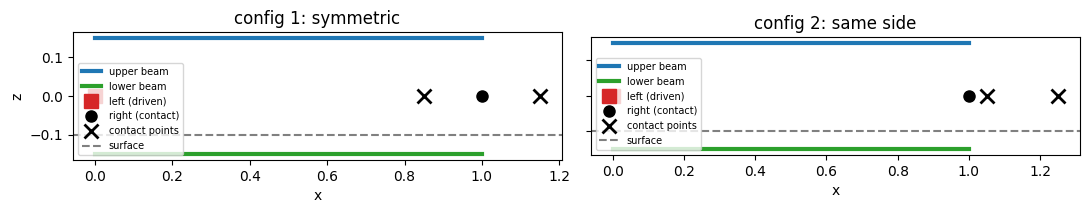

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
for ax, (label, (dx1, dx2)) in zip(axes, configs.items()):
    frame, node_left, node_right, c1, c2, beams = build_frame(dx1, dx2)
    for name, (beam, offA, offB) in beams.items():
        color = "tab:blue" if name == "upper" else "tab:green"
        ax.plot([beam.xa0, beam.xb0], [beam.za0, beam.zb0], "-", color=color, lw=3, label=f"{name} beam")
    ax.plot(0.0, 0.0, "s", color="tab:red", markersize=10, label="left (driven)")
    ax.plot(L, 0.0, "o", color="black", markersize=8, label="right (contact)")
    ax.plot([L + dx1, L + dx2], [0.0, 0.0], "kx", markersize=10, mew=2, label="contact points")
    ax.axhline(-contact_clearance, color="gray", ls="--", lw=1.5, label="surface")
    ax.set_aspect("equal")
    ax.set_xlabel("x"); ax.set_title(label)
    ax.legend(fontsize=7, loc="lower left")
axes[0].set_ylabel("z")
plt.tight_layout()
plt.show()

## Apply the load path and solve

Left body's `w` driven down 0.2, then back up to 0 -- two legs, via
`Frame.solve_path_with_contact`, continuing warm-started (displacement solution *and* every
beam's persistent local force state) across the direction reversal. After every converged step,
each contact point is checked active-set style and the step re-solved if either point's status
changed.

In [4]:
results = {}
for label, (dx1, dx2) in configs.items():
    frame, node_left, node_right, c1, c2, beams = build_frame(dx1, dx2)
    legs = [{(node_left, 1): -0.2}, {(node_left, 1): 0.0}]
    history = frame.solve_path_with_contact(
        legs, contacts=[c1, c2], n_steps_per_leg=100, tol=1e-7,
        max_newton=30, max_step_doublings=6, max_contact_iters=8, verbose=False)
    results[label] = dict(frame=frame, node_left=node_left, node_right=node_right,
                           c1=c1, c2=c2, beams=beams, history=history)
    print(f"{label}: solved in {len(history)} steps, "
          f"final right-node raw DOF (w1, u_c, w2) = {history[-1].u[3*node_right:3*node_right+3]}")

config 1: symmetric: solved in 200 steps, final right-node raw DOF (w1, u_c, w2) = [-1.48561766e-06  1.78580804e-09 -1.48479290e-06]


config 2: same side: solved in 200 steps, final right-node raw DOF (w1, u_c, w2) = [-1.48506782e-06  1.78580804e-09 -1.48451798e-06]


## Contact-point trajectories: which point actually touches, and when

Each point's *penetration* (positive = touching/pinned to the surface) plotted against the
left body's driven displacement, down and back up. Configuration 1 (symmetric points) still only
brings *one* point fully into contact over this stroke -- the other's penetration approaches but
does not quite reach zero -- because the mechanism's parasitic rotation (already seen in
`parallel_beam_flexure`, a real large-deflection effect of a simple two-beam parallel guide, not
a numerical artifact) breaks the naive left-right symmetry even for "symmetric" contact points.
Configuration 2 (both points offset the same direction) shows this same effect much more
clearly, by design: the farther point (larger `|dx|`) always reaches the surface, the nearer one
never does over this stroke -- directly demonstrating why two-point contact needs to handle the
"only one point really touches" case as a first-class outcome, not an edge case.

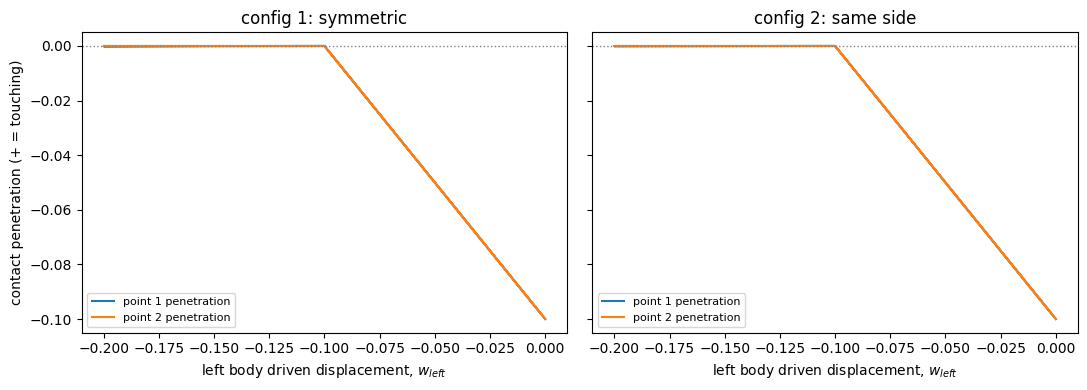

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (label, res) in zip(axes, results.items()):
    hist = res["history"]
    left_w = np.array([s.u[3 * res["node_left"] + 1] for s in hist])
    w1 = np.array([s.u[3 * res["node_right"] + 0] for s in hist])
    w2 = np.array([s.u[3 * res["node_right"] + 2] for s in hist])
    pen1 = -contact_clearance - w1   # positive = touching
    pen2 = -contact_clearance - w2
    ax.plot(left_w, pen1, label="point 1 penetration")
    ax.plot(left_w, pen2, label="point 2 penetration")
    ax.axhline(0.0, color="gray", lw=1, ls=":")
    ax.set_xlabel("left body driven displacement, $w_{left}$")
    ax.set_title(label)
    ax.legend(fontsize=8)
axes[0].set_ylabel("contact penetration (+ = touching)")
plt.tight_layout()
plt.show()

## Deformed shapes at a few points along the path

Both beams, plotted at the start, at maximum downward stroke, and back at the end of the return
leg, for each configuration.

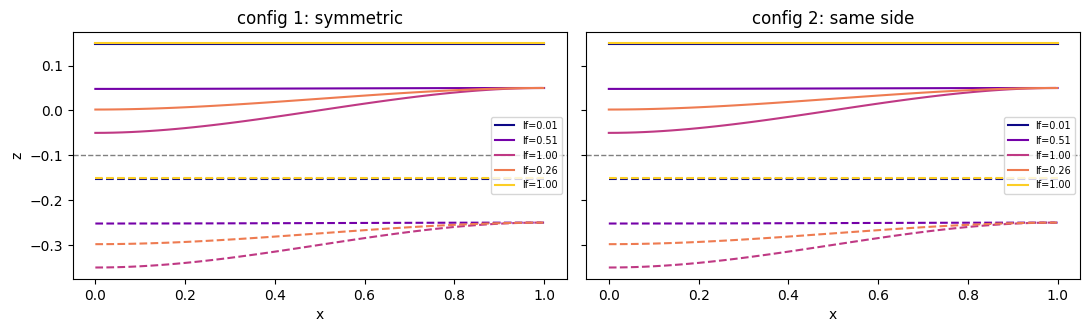

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharey=True)
for ax, (label, res) in zip(axes, results.items()):
    hist = res["history"]
    node_left, node_right, beams = res["node_left"], res["node_right"], res["beams"]
    snap_indices = [0, len(hist) // 4, 100 - 1, 100 + len(hist) // 8, len(hist) - 1]
    colors = plt.cm.plasma(np.linspace(0, 0.9, len(snap_indices)))
    for idx, color in zip(snap_indices, colors):
        step = hist[idx]
        dofL = step.u[3 * node_left: 3 * node_left + 3]
        q_rawR = step.u[3 * node_right: 3 * node_right + 3]
        node_right_obj = res["frame"].nodes[node_right]
        q_stdR = node_right_obj.G @ q_rawR
        for name, (beam, offA, offB) in beams.items():
            ls = "-" if name == "upper" else "--"
            dofA = anchor_dof(dofL, *offA)
            dofB = anchor_dof(q_stdR, *offB)
            result = beam.compute(dofA, dofB)
            shape = beam.deformed_shape_global(dofA, result)
            ax.plot(shape[:, 0], shape[:, 1], ls, color=color,
                    label=f"lf={step.load_factor:.2f}" if name == "upper" else None)
    ax.axhline(-contact_clearance, color="gray", ls="--", lw=1)
    ax.set_aspect("equal")
    ax.set_xlabel("x"); ax.set_title(label)
    ax.legend(fontsize=7)
axes[0].set_ylabel("z")
plt.tight_layout()
plt.show()

## Return-to-start check

With no plastic/path-dependent element in the beams themselves, and both contact points
released again by the time the left body returns to `w = 0`, the mechanism should return very
close to its undeformed state at the end of the "back up" leg.

In [7]:
for label, res in results.items():
    u_final = res["history"][-1].u
    c1_active, c2_active = res["c1"].active, res["c2"].active
    print(f"{label}: final u = {u_final}, contact active at end = ({c1_active}, {c2_active})")

config 1: symmetric: final u = [ 0.00000000e+00  0.00000000e+00  0.00000000e+00 -1.48561766e-06
  1.78580804e-09 -1.48479290e-06], contact active at end = (False, False)
config 2: same side: final u = [ 0.00000000e+00  0.00000000e+00  0.00000000e+00 -1.48506782e-06
  1.78580804e-09 -1.48451798e-06], contact active at end = (False, False)


## Penalty (compliant) contact: does it agree with active-set, and what does softness change?

The two contact points above were pinned exactly to the surface once touching (active-set,
matching the original prototype's `Rigid_Contact`) -- an idealization of a perfectly rigid
surface. A real jaw (especially a 3D-printed one, e.g. PLA rather than aluminum) has finite local
contact stiffness: it should actually penetrate a little, and the two points should carry
different loads depending on how stiff that local compliance is relative to the beams'
transverse stiffness.

`src/flexsim/contact.py`'s `PenaltyFlatContact` implements this: a one-sided linear spring
(`F = -k * penetration` when penetrating, `0` otherwise), attached to an *ordinary* node via the
same anchor-offset machinery already used for beams -- no `G`-matrix reparametrization needed,
since a point force doesn't require redefining the body's DOF basis the way active-set contact
checking did.

First check: does penalty contact agree with the active-set result in the limit of a very stiff
surface? It should, since a large `k` should behave like a near-rigid stop.

In [8]:
from flexsim.rigid import anchor_dof


def build_penalty_frame(dx1, dx2, k):
    """Same geometry as build_frame, but the right body is an ordinary
    node (not a contact node) with two PenaltyFlatContact points attached
    via the standard anchor-offset mechanism."""
    n_seg = n_segments_from_thickness(L, thickness, spacing_factor=2.0)
    left_pos = (0.0, 0.0)
    right_pos = (L, 0.0)
    offset_a_up, offset_b_up = (0.0, h / 2), (0.0, h / 2)
    offset_a_lo, offset_b_lo = (0.0, -h / 2), (0.0, -h / 2)

    xa, za = anchor_initial_position(*left_pos, *offset_a_up)
    xb, zb = anchor_initial_position(*right_pos, *offset_b_up)
    beam_upper = JirasekBeam(xa0=xa, za0=za, xb0=xb, zb0=zb,
                              E=E, width=width, thickness=thickness, n_seg=n_seg)
    xa, za = anchor_initial_position(*left_pos, *offset_a_lo)
    xb, zb = anchor_initial_position(*right_pos, *offset_b_lo)
    beam_lower = JirasekBeam(xa0=xa, za0=za, xb0=xb, zb0=zb,
                              E=E, width=width, thickness=thickness, n_seg=n_seg)

    frame = Frame()
    node_left = frame.add_node(*left_pos)
    node_right = frame.add_node(*right_pos)   # ordinary node -- no G reparametrization
    frame.add_element(node_left, node_right, beam_upper, offset_a=offset_a_up, offset_b=offset_b_up)
    frame.add_element(node_left, node_right, beam_lower, offset_a=offset_a_lo, offset_b=offset_b_lo)

    surface_z = right_pos[1] - contact_clearance
    contact1 = frame.add_penalty_contact(node_right, offset=(dx1, 0.0), surface_z=surface_z, k=k)
    contact2 = frame.add_penalty_contact(node_right, offset=(dx2, 0.0), surface_z=surface_z, k=k)

    frame.fix(node_left, 0, 0.0)
    frame.fix(node_left, 1, -0.2)
    frame.fix(node_left, 2, 0.0)
    frame.load(node_right, 0, 0.0)
    frame.load(node_right, 1, 0.0)
    frame.load(node_right, 2, 0.0)
    return frame, node_left, node_right, contact1, contact2


# Config 2 (single-point-touching case) driven to the same -0.2 stroke used
# above, single leg (no need for the down/up path here -- just checking the
# contact law itself).
dx1, dx2 = configs["config 2: same side"]

frame_as, node_left_as, node_right_as, c1_as, c2_as, beams_as = build_frame(dx1, dx2)
legs = [{(node_left_as, 1): -0.2}]
hist_as = frame_as.solve_path_with_contact(
    legs, contacts=[c1_as, c2_as], n_steps_per_leg=150, tol=1e-8,
    max_newton=30, max_step_doublings=6, max_contact_iters=8)
u_as_raw = hist_as[-1].u[3 * node_right_as: 3 * node_right_as + 3]
G_as = frame_as.nodes[node_right_as].G
u_as_std = G_as @ u_as_raw
print("active-set right body [u, w, phi] (via G):", u_as_std)

print(f"{'k':>10} {'u':>12} {'w':>12} {'phi':>12}")
for k in [1.0, 1e4]:
    frame_p, node_left_p, node_right_p, c1_p, c2_p = build_penalty_frame(dx1, dx2, k)
    hist_p = frame_p.solve(n_steps=80, tol=1e-6, max_newton=25, max_step_doublings=3)
    u_p = hist_p[-1].u[3 * node_right_p: 3 * node_right_p + 3]
    print(f"{k:10.0e} {u_p[0]:12.6f} {u_p[1]:12.6f} {u_p[2]:12.6f}")

active-set right body [u, w, phi] (via G): [-0.00602319 -0.09992352 -0.00030594]
         k            u            w          phi


     1e+00    -0.006023    -0.099924    -0.000306


     1e+04    -0.006023    -0.099924    -0.000306


As `k` grows, the penalty result converges to the active-set solution (matches to ~5
significant figures by `k = 1e4`) -- a good cross-check that both contact formulations describe
the same underlying physics, and that a "rigid enough" penalty spring is a reasonable stand-in
for an exact constraint.

## A softer, PLA-like surface: real penetration and an uneven load split

Now sweep `k` down through a much softer range and look at each point's actual penetration and
force. This is the regime a compliant (e.g. 3D-printed) jaw surface would live in: real,
non-negligible local penetration, and -- because of the same parasitic rotation already seen
throughout this example -- the two contact points don't carry equal load even for symmetric
placement. A true distributed-contact model (stress varying continuously along a real contact
line, not just two lumped points) would be the natural next step once this needs to inform actual
part design; a good way to set `k` itself to a physically meaningful value, rather than an
arbitrary one, would be **Hertzian line-contact theory** (line-on-flat contact stiffness from the
two materials' effective modulus and the contact geometry's radius of curvature) once real
material and geometry parameters are on hand.

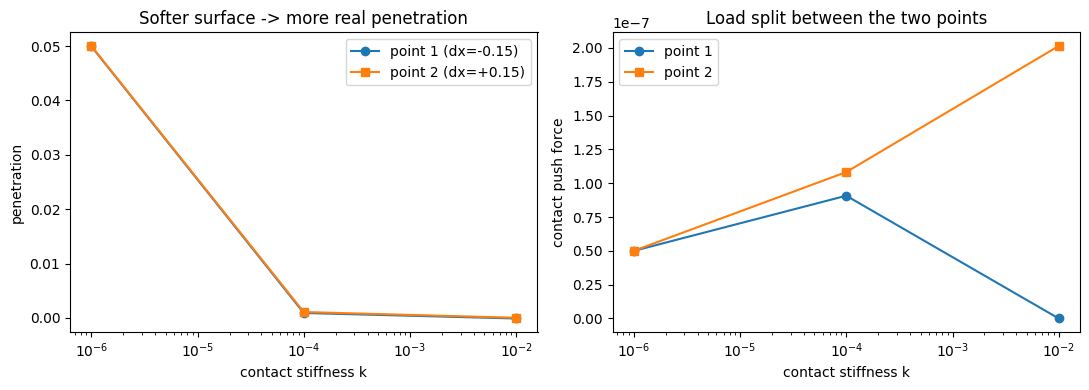

         k       pen1       pen2           f1           f2    f1/f2
     1e-06    0.04996    0.05001    4.996e-08    5.001e-08    0.999
     1e-04    0.00091    0.00108    9.074e-08    1.082e-07    0.838
     1e-02   -0.00011    0.00002   -0.000e+00    2.014e-07   -0.000


In [9]:
dx1_sym, dx2_sym = configs["config 1: symmetric"]
ks = np.array([1e-6, 1e-4, 1e-2])
pen1_list, pen2_list, f1_list, f2_list = [], [], [], []

for k in ks:
    frame_p, node_left_p, node_right_p, c1_p, c2_p = build_penalty_frame(dx1_sym, dx2_sym, k)
    hist_p = frame_p.solve(n_steps=80, tol=1e-6, max_newton=25, max_step_doublings=3)
    dofR = hist_p[-1].u[3 * node_right_p: 3 * node_right_p + 3]
    a1 = anchor_dof(dofR, dx1_sym, 0.0)
    a2 = anchor_dof(dofR, dx2_sym, 0.0)
    f1, _, d1 = c1_p.compute(a1)
    f2, _, d2 = c2_p.compute(a2)
    pen1_list.append(d1); pen2_list.append(d2)
    f1_list.append(-f1[1]); f2_list.append(-f2[1])   # sign-flip: positive = pushing force magnitude

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].semilogx(ks, pen1_list, "o-", label="point 1 (dx=-0.15)")
axes[0].semilogx(ks, pen2_list, "s-", label="point 2 (dx=+0.15)")
axes[0].set_xlabel("contact stiffness k"); axes[0].set_ylabel("penetration")
axes[0].set_title("Softer surface -> more real penetration")
axes[0].legend()

axes[1].semilogx(ks, f1_list, "o-", label="point 1")
axes[1].semilogx(ks, f2_list, "s-", label="point 2")
axes[1].set_xlabel("contact stiffness k"); axes[1].set_ylabel("contact push force")
axes[1].set_title("Load split between the two points")
axes[1].legend()
plt.tight_layout()
plt.show()

print(f"{'k':>10} {'pen1':>10} {'pen2':>10} {'f1':>12} {'f2':>12} {'f1/f2':>8}")
for k, p1, p2, f1v, f2v in zip(ks, pen1_list, pen2_list, f1_list, f2_list):
    ratio = f1v / f2v if f2v != 0 else float('nan')
    print(f"{k:10.0e} {p1:10.5f} {p2:10.5f} {f1v:12.3e} {f2v:12.3e} {ratio:8.3f}")